In [4]:
import numpy as np
import time
import torch
import matplotlib.pyplot as plt
plt.rc('text', usetex=False)
import multiprocessing as mp
from typing import Union


from abc import ABC
from epde.preprocessing.cheb import process_point_cheb

from epde.preprocessing.deriv_calculators import Heatmap, AbstractDeriv, AdaptiveFiniteDeriv, PolynomialDeriv, SpectralDeriv, TotalVariation

In [6]:
def masked_mse(arr1, arr2, inner_start=5, inner_end=27):
    """
    Вычисляет MSE между двумя массивами, игнорируя внутреннюю часть [inner_start:inner_end, inner_start:inner_end].
    
    Параметры:
    ----------
    arr1, arr2 : numpy.ndarray
        Двумерные массивы одинакового размера.
    inner_start, inner_end : int
        Границы внутренней области, которую нужно исключить из расчёта.
        
    Возвращает:
    -----------
    mse : float
        Среднеквадратичная ошибка (без учета внутренней части).
    """
    # Создаём маску: True там, где элементы ДОЛЖНЫ учитываться в MSE (вне внутренней части)
    mask = np.ones_like(arr1, dtype=bool)
    mask[inner_start:inner_end, inner_start:inner_end] = False
    
    # Применяем маску к обоим массивам
    masked_arr1 = arr1[mask]
    masked_arr2 = arr2[mask]
    
    # Вычисляем MSE только по валидным элементам
    squared_errors = (masked_arr1 - masked_arr2) ** 2
    mse = np.mean(squared_errors)
    
    return mse

Mean Squared Error (MSE) for noise level 0:
  u_xx: 3.9068214400835797
  u_tt: 2.441678803677325
Mean Squared Error (MSE) for noise level 0.005:
  u_xx: 106.65165696620289
  u_tt: 1796.4747429087008
Mean Squared Error (MSE) for noise level 0.01:
  u_xx: 405.10996365963797
  u_tt: 8660.790700264568


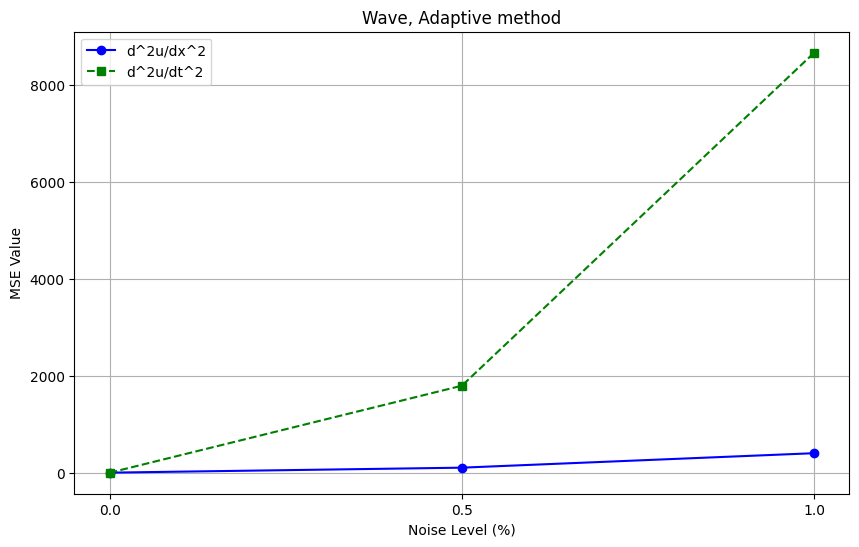

In [7]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_xx = []
mse_values_u_tt = []

for noise in noise_levels:
    u_xx = np.load(f'Wave_Gradient_xx_noise{noise}.npy')
    u_tt = np.load(f'Wave_Gradient_tt_noise{noise}.npy')
    
    gradient_xx = np.load(f'Wave_Adaptive_xx_noise{noise}.npy')
    gradient_tt = np.load(f'Wave_Adaptive_tt_noise{noise}.npy')

    # Вычисление MSE для каждого случая
    mse_u_xx = masked_mse(u_xx, gradient_xx, inner_start=5, inner_end=27)
    mse_u_tt = masked_mse(u_tt, gradient_tt, inner_start=5, inner_end=27)
    
    mse_values_u_xx.append(mse_u_xx)
    mse_values_u_tt.append(mse_u_tt)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_xx: {mse_u_xx}')
    print(f'  u_tt: {mse_u_tt}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_xx, marker='o', linestyle='-', color='b', label='d^2u/dx^2')
plt.plot(noise_levels_percent, mse_values_u_tt, marker='s', linestyle='--', color='g', label='d^2u/dt^2')

plt.title('Wave, Adaptive method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('Wave_Adaptive_error.pdf', format='pdf')
plt.show()


Mean Squared Error (MSE) for noise level 0:
  u_xx: 0.0008864899413885722
  u_tt: 1.3526763126900033e-08
Mean Squared Error (MSE) for noise level 0.005:
  u_xx: 83.38506788894583
  u_tt: 130.69803601461575
Mean Squared Error (MSE) for noise level 0.01:
  u_xx: 665.1299869790121
  u_tt: 472.6915071982533


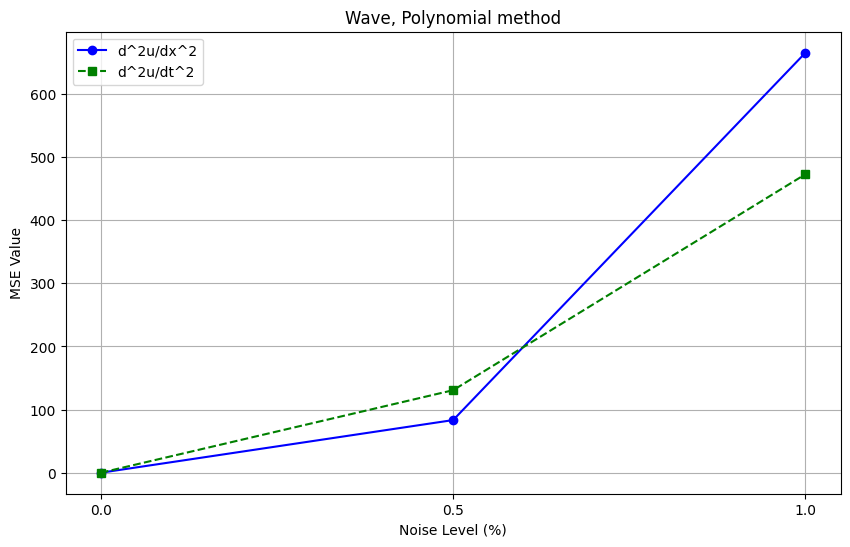

In [8]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_xx = []
mse_values_u_tt = []

for noise in noise_levels:
    u_xx = np.load(f'Wave_Gradient_xx_noise{noise}.npy')
    u_tt = np.load(f'Wave_Gradient_tt_noise{noise}.npy')
    
    gradient_xx = np.load(f'Wave_Polynomial_xx_noise{noise}.npy')
    gradient_tt = np.load(f'Wave_Polynomial_tt_noise{noise}.npy')

    u_xx = u_xx[5:27, 5:27]
    u_tt = u_tt[5:27, 5:27]
    

    gradient_xx = gradient_xx[5:27, 5:27]
    gradient_tt = gradient_tt[5:27, 5:27]
        
    # Вычисление MSE для каждого случая
    mse_u_xx = masked_mse(u_xx, gradient_xx, inner_start=5, inner_end=27)
    mse_u_tt = masked_mse(u_tt, gradient_tt, inner_start=5, inner_end=27)
    
    mse_values_u_xx.append(mse_u_xx)
    mse_values_u_tt.append(mse_u_tt)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_xx: {mse_u_xx}')
    print(f'  u_tt: {mse_u_tt}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_xx, marker='o', linestyle='-', color='b', label='d^2u/dx^2')
plt.plot(noise_levels_percent, mse_values_u_tt, marker='s', linestyle='--', color='g', label='d^2u/dt^2')

plt.title('Wave, Polynomial method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('Wave_Polynomial_error.pdf', format='pdf')
plt.show()


Mean Squared Error (MSE) for noise level 0:
  u_xx: 4330.284081305995
  u_tt: 4791.33907777723
Mean Squared Error (MSE) for noise level 0.005:
  u_xx: 5164.471895114846
  u_tt: 5031.076304832127
Mean Squared Error (MSE) for noise level 0.01:
  u_xx: 6266.430358629303
  u_tt: 7554.846818027328


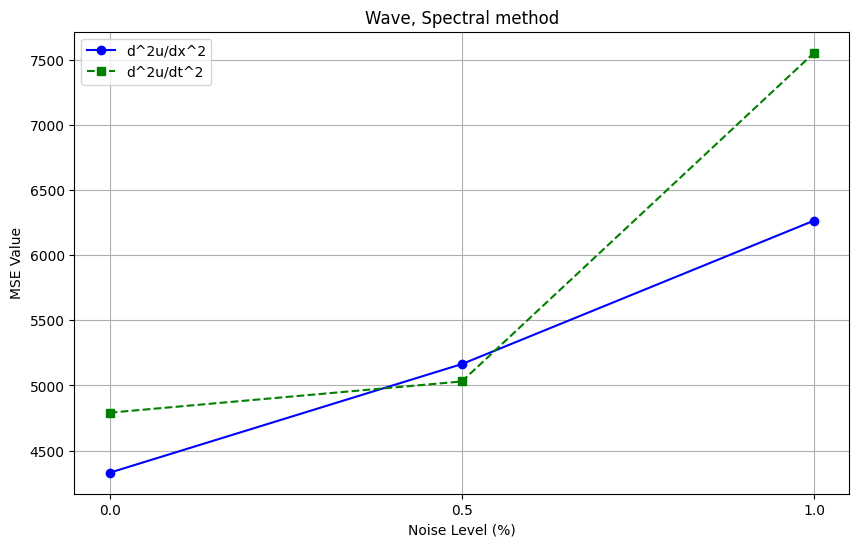

In [9]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_xx = []
mse_values_u_tt = []

for noise in noise_levels:
    u_xx = np.load(f'Wave_Gradient_xx_noise{noise}.npy')
    u_tt = np.load(f'Wave_Gradient_tt_noise{noise}.npy')
    
    gradient_xx = np.load(f'Wave_Spectral_xx_noise{noise}.npy')
    gradient_tt = np.load(f'Wave_Spectral_tt_noise{noise}.npy')

    u_xx = u_xx[5:27, 5:27]
    u_tt = u_tt[5:27, 5:27]
    

    gradient_xx = gradient_xx[5:27, 5:27]
    gradient_tt = gradient_tt[5:27, 5:27]
        
    # Вычисление MSE для каждого случая
    mse_u_xx = masked_mse(u_xx, gradient_xx, inner_start=5, inner_end=27)
    mse_u_tt = masked_mse(u_tt, gradient_tt, inner_start=5, inner_end=27)
    
    mse_values_u_xx.append(mse_u_xx)
    mse_values_u_tt.append(mse_u_tt)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_xx: {mse_u_xx}')
    print(f'  u_tt: {mse_u_tt}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_xx, marker='o', linestyle='-', color='b', label='d^2u/dx^2')
plt.plot(noise_levels_percent, mse_values_u_tt, marker='s', linestyle='--', color='g', label='d^2u/dt^2')

plt.title('Wave, Spectral method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('Wave_Spectral_error.pdf', format='pdf')
plt.show()


Mean Squared Error (MSE) for noise level 0:
  u_xx: 6552.968701506239
  u_tt: 25.721310528289305
Mean Squared Error (MSE) for noise level 0.005:
  u_xx: 7255.293044289083
  u_tt: 433.5564718478172
Mean Squared Error (MSE) for noise level 0.01:
  u_xx: 8576.680719127053
  u_tt: 2610.752985568372


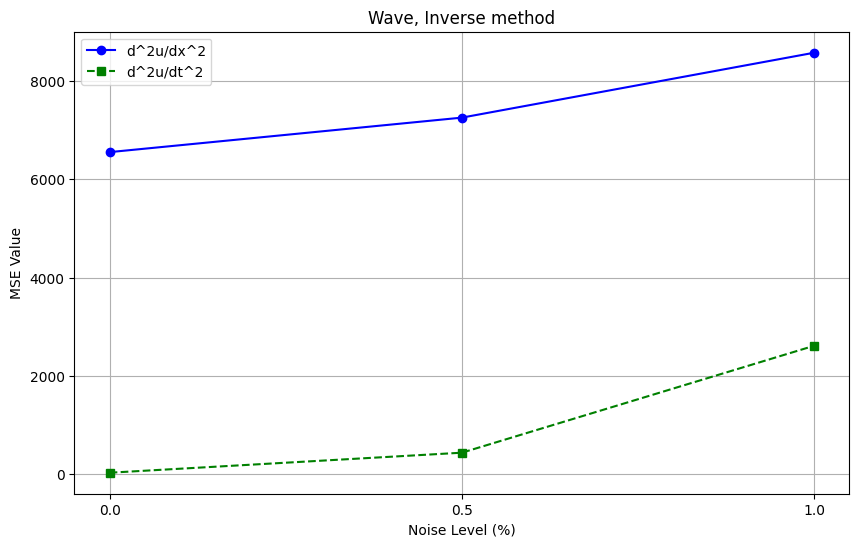

In [10]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_xx = []
mse_values_u_tt = []

for noise in noise_levels:
    u_xx = np.load(f'Wave_Gradient_xx_noise{noise}.npy')
    u_tt = np.load(f'Wave_Gradient_tt_noise{noise}.npy')
    
    gradient_xx = np.load(f'Wave_Inverse_xx_noise{noise}.npy')
    gradient_tt = np.load(f'Wave_Inverse_tt_noise{noise}.npy')

    u_xx = u_xx[5:27, 5:27]
    u_tt = u_tt[5:27, 5:27]
    

    gradient_xx = gradient_xx[5:27, 5:27]
    gradient_tt = gradient_tt[5:27, 5:27]
       
    # Вычисление MSE для каждого случая
    mse_u_xx = masked_mse(u_xx, gradient_xx, inner_start=5, inner_end=27)
    mse_u_tt = masked_mse(u_tt, gradient_tt, inner_start=5, inner_end=27)
    
    mse_values_u_xx.append(mse_u_xx)
    mse_values_u_tt.append(mse_u_tt)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_xx: {mse_u_xx}')
    print(f'  u_tt: {mse_u_tt}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_xx, marker='o', linestyle='-', color='b', label='d^2u/dx^2')
plt.plot(noise_levels_percent, mse_values_u_tt, marker='s', linestyle='--', color='g', label='d^2u/dt^2')

plt.title('Wave, Inverse method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('Wave_Inverse_error.pdf', format='pdf')
plt.show()


Mean Squared Error (MSE) for noise level 0:
  u_xx: 9867.93920981192
  u_tt: 63.359665039400284
Mean Squared Error (MSE) for noise level 0.005:
  u_xx: 10748.539169292038
  u_tt: 5073.454844327665
Mean Squared Error (MSE) for noise level 0.01:
  u_xx: 15496.65496065426
  u_tt: 24050.041216526995


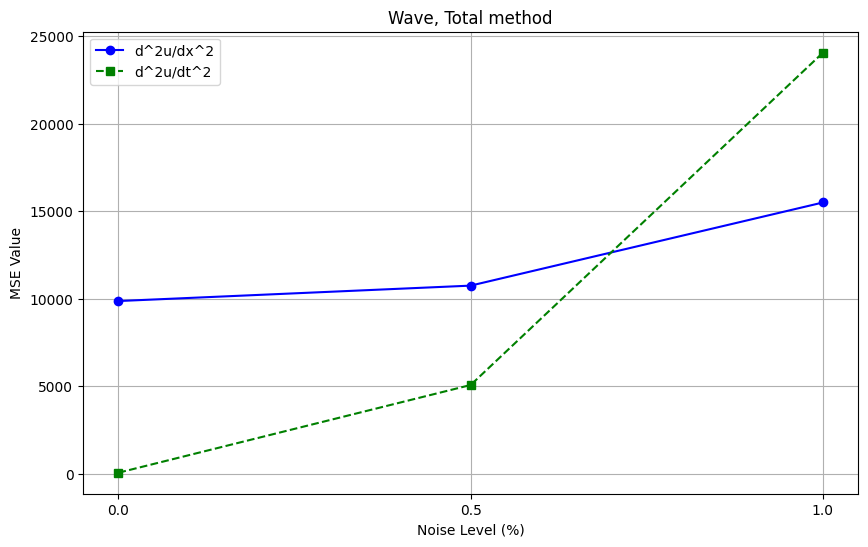

In [11]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_xx = []
mse_values_u_tt = []

for noise in noise_levels:
    u_xx = np.load(f'Wave_Gradient_xx_noise{noise}.npy')
    u_tt = np.load(f'Wave_Gradient_tt_noise{noise}.npy')
    
    gradient_xx = np.load(f'Wave_Total_xx_noise{noise}.npy')
    gradient_tt = np.load(f'Wave_Total_tt_noise{noise}.npy')
        
    # Вычисление MSE для каждого случая
    mse_u_xx = masked_mse(u_xx, gradient_xx, inner_start=5, inner_end=27)
    mse_u_tt = masked_mse(u_tt, gradient_tt, inner_start=5, inner_end=27)
    
    mse_values_u_xx.append(mse_u_xx)
    mse_values_u_tt.append(mse_u_tt)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_xx: {mse_u_xx}')
    print(f'  u_tt: {mse_u_tt}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_xx, marker='o', linestyle='-', color='b', label='d^2u/dx^2')
plt.plot(noise_levels_percent, mse_values_u_tt, marker='s', linestyle='--', color='g', label='d^2u/dt^2')

plt.title('Wave, Total method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('Wave_Total_error.pdf', format='pdf')
plt.show()
